# 02 - LoRA on SAM 3 (team stack)
The LoRA adaptation arm on the native `sam3` package, the shared team stack
(`Sam3MedSeg`). Build the model, verify the injection targets, and verify the
trainable-param counts of `finetune_mode="lora"`.

History (in git, not the working tree): the SAM 1 prototype lives in this
notebook's earlier versions (147K/93.7M, 0.157%); the HF-transformers SAM 3
verification was notebook 03_Sam3_explore.ipynb, removed after the team
standardized on the native stack (see commit 6d38175).

**Kernel: select the `sam3-native` env** (the only one with the `sam3` package).

In [1]:
#autoreload, so edits to .py files show without restarting
%load_ext autoreload
%autoreload 2

In [2]:
import sys; sys.path.insert(0, "../src")
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from medseg.data.medseg_data import DataConfig, build_dataloaders
from medseg.models import Sam3MedSeg
from medseg.engine.metrics import dice_score, nsd
from medseg.utils.device import get_device

device = get_device()
print("device:", device)     # sam3-native env; mps on this Mac

# --- helpers used by the results sections below ---
@torch.no_grad()
def predict_prob(model, image):
    """One image -> 256x256 lesion-probability map (model outputs 1008, resized down)."""
    model.eval()
    logits = model(image.unsqueeze(0).to(device))
    prob = torch.sigmoid(logits)
    return F.interpolate(prob, size=image.shape[-2:], mode="bilinear", align_corners=False)[0, 0].cpu()

def dice_of(prob, gt, thr=0.5):
    """Single-image Dice, for the viz titles."""
    pred = (prob > thr).float()
    return (2 * (pred * gt).sum() / (pred.sum() + gt.sum() + 1e-6)).item()

@torch.no_grad()
def eval_split(model, ds):
    """Mean Dice + NSD over a whole split, matching the trainer's val method (at 1008)."""
    model.eval()
    dices, nsds = [], []
    for i in range(len(ds)):
        s = ds[i]
        logits = model(s["image"].unsqueeze(0).to(device))
        mask = F.interpolate(s["mask"].unsqueeze(0).to(device), size=logits.shape[-2:], mode="nearest")
        prob = torch.sigmoid(logits)
        dices.append(dice_score(prob, mask))
        nsds.append(nsd(prob, mask, tol=2))
    return sum(dices) / len(dices), sum(nsds) / len(nsds)

device: mps


/Users/nikhilclaude/anaconda3/envs/sam3-native/lib/python3.12/site-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error _ssl.c:993: The handshake operation timed out>
  data = fetch_version_info()


## 1. Unit tests: LoRALayer / LinearWithLoRA / LoRA_qkv slice isolation

In [3]:
!pytest ../tests/test_lora.py -v

============================= test session starts ==============================
platform darwin -- Python 3.12.13, pytest-9.1.1, pluggy-1.6.0 -- /Users/nikhilclaude/anaconda3/envs/sam3-native/bin/python3.12
cachedir: .pytest_cache
rootdir: /Users/nikhilclaude/Documents/Projects/DeepLearning/group_project
plugins: anyio-4.14.2
collected 5 items                                                              

../tests/test_lora.py::test_output_shape PASSED                          [ 20%]
../tests/test_lora.py::test_zero_at_init PASSED                          [ 40%]
../tests/test_lora.py::test_param_count PASSED                           [ 60%]
../tests/test_lora.py::test_linear_with_lora PASSED                      [ 80%]
../tests/test_lora.py::test_lora_qkv_slices PASSED                       [100%]

============================== 5 passed in 0.43s ===============================


## 2. Build the LoRA model (once) + injection targets
Build `Sam3MedSeg(finetune_mode="lora")` once and reuse it everywhere below, plus an
untrained `baseline` for the before/after viz. Each builds the frozen SAM 3 backbone
internally (~1-2 min) — these are the ONLY two model builds in the notebook. The LoRA
is injected at construction into every vision-backbone block's fused qkv.

In [4]:
# The two model builds, reused by every section below (~1-2 min each on Mac).
model = Sam3MedSeg(finetune_mode="lora").to(device)      # gets each dataset's trained weights later
baseline = Sam3MedSeg(finetune_mode="lora").to(device)   # stays untrained = the before-picture

# injection targets: 32 fused-qkv layers in the vision backbone, each now wrapped by LoRA_qkv
blocks = model.backbone.backbone.vision_backbone.trunk.blocks
print(f"{len(blocks)} vision blocks | block[0].attn.qkv is now a {type(blocks[0].attn.qkv).__name__}")
print(blocks[0].attn.qkv)

/Users/nikhilclaude/Documents/Projects/DeepLearning/group_project/vendor/sam3-repo/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/nikhilclaude/Documents/Projects/DeepLearning/group_project/vendor/sam3-repo/sam3/model/sam3_video_inference.py:800: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.bfloat16)
/Users/nikhilclaude/Documents/Projects/DeepLearning/group_project/vendor/sam3-repo/sam3/model/sam3_video_inference.py:908: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.bfloat16)
/Users/nikhilclaude/anaconda3/envs/sam3-native/lib/python3.12/site-packages/timm/models/layers/__in

32 vision blocks | block[0].attn.qkv is now a LoRA_qkv
LoRA_qkv(
  (qkv): Linear(in_features=1024, out_features=3072, bias=True)
  (lora_q): LoRALayer(
    (A): Linear(in_features=1024, out_features=4, bias=False)
    (B): Linear(in_features=4, out_features=1024, bias=False)
  )
  (lora_v): LoRALayer(
    (A): Linear(in_features=1024, out_features=4, bias=False)
    (B): Linear(in_features=4, out_features=1024, bias=False)
  )
)


## 3. Trainable params (verify the injection)
Freeze the 455M backbone, train only the LoRA adapters + FPN head. Counted on the
`model` built above. Expected:
`1,066,113 / 455,105,921  (0.2343%)  = 524,288 adapters (32 x 2 x 2*4*1024) + 541,825 head`.
Any other number means the injection state is wrong (see docs/lora.md).

In [5]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"{trainable:,} / {total:,} trainable  ({100*trainable/total:.4f}%)")

1,066,113 / 455,105,921 trainable  (0.2343%)


## 4. Results: both datasets side by side
One section per dataset via `run_dataset(...)` (defined below). Each loads that
dataset's trained checkpoint into `model`, evaluates its whole test set (mean
Dice/NSD), and shows 5 examples (image | GT | untrained | trained), then a comparison.

Needs both full checkpoints locally: `checkpoints/sam3_lora_busi_full/best.pt` and
`.../sam3_lora_kvasir_full/best.pt` (scp the Kvasir one down from the cluster first).

In [6]:
def run_dataset(dataset, model, baseline, n_show=5):
    """Load `dataset`'s trained weights into `model`, evaluate its test set, and show
    a few examples as image | GT | untrained | trained. `dataset` is "busi" or "kvasir"
    (drives both the checkpoint and the matching test data, so they can't be mismatched).
    `baseline` is the untrained model (random head) reused as the before-picture."""
    ckpt = torch.load(f"../checkpoints/sam3_lora_{dataset}_full/best.pt", map_location=device)
    model.load_state_dict(ckpt["model"])
    test_ds = build_dataloaders(DataConfig.from_yaml(f"../configs/data/{dataset}.yaml"))["test"].dataset
    dice, nsd_score = eval_split(model, test_ds)
    print(f"{dataset}: ckpt epoch {ckpt['epoch']} (val {ckpt['dice']:.4f})  |  "
          f"TEST {len(test_ds)} imgs -> mean Dice {dice:.4f}  mean NSD {nsd_score:.4f}")

    fig, axes = plt.subplots(n_show, 4, figsize=(16, 4 * n_show))
    for row in range(n_show):
        s = test_ds[row]
        img, m = s["image"], s["mask"][0]
        prob_u = predict_prob(baseline, img)     # untrained (random head)
        prob_t = predict_prob(model, img)        # trained
        img_np = img.permute(1, 2, 0).numpy()
        axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"{dataset} test[{row}]")
        axes[row, 1].imshow(img_np); axes[row, 1].imshow(m, cmap="Reds", alpha=0.5)
        axes[row, 1].set_title("ground truth")
        axes[row, 2].imshow(prob_u, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title(f"untrained\ndice {dice_of(prob_u, m):.3f}")
        axes[row, 3].imshow(prob_t, cmap="viridis", vmin=0, vmax=1)
        axes[row, 3].set_title(f"trained\ndice {dice_of(prob_t, m):.3f}")
        for a in axes[row]:
            a.axis("off")
    plt.tight_layout(); plt.show()
    return dice, nsd_score

busi: ckpt epoch 17 (val 0.7749)  |  TEST 131 imgs -> mean Dice 0.7670  mean NSD 0.2191


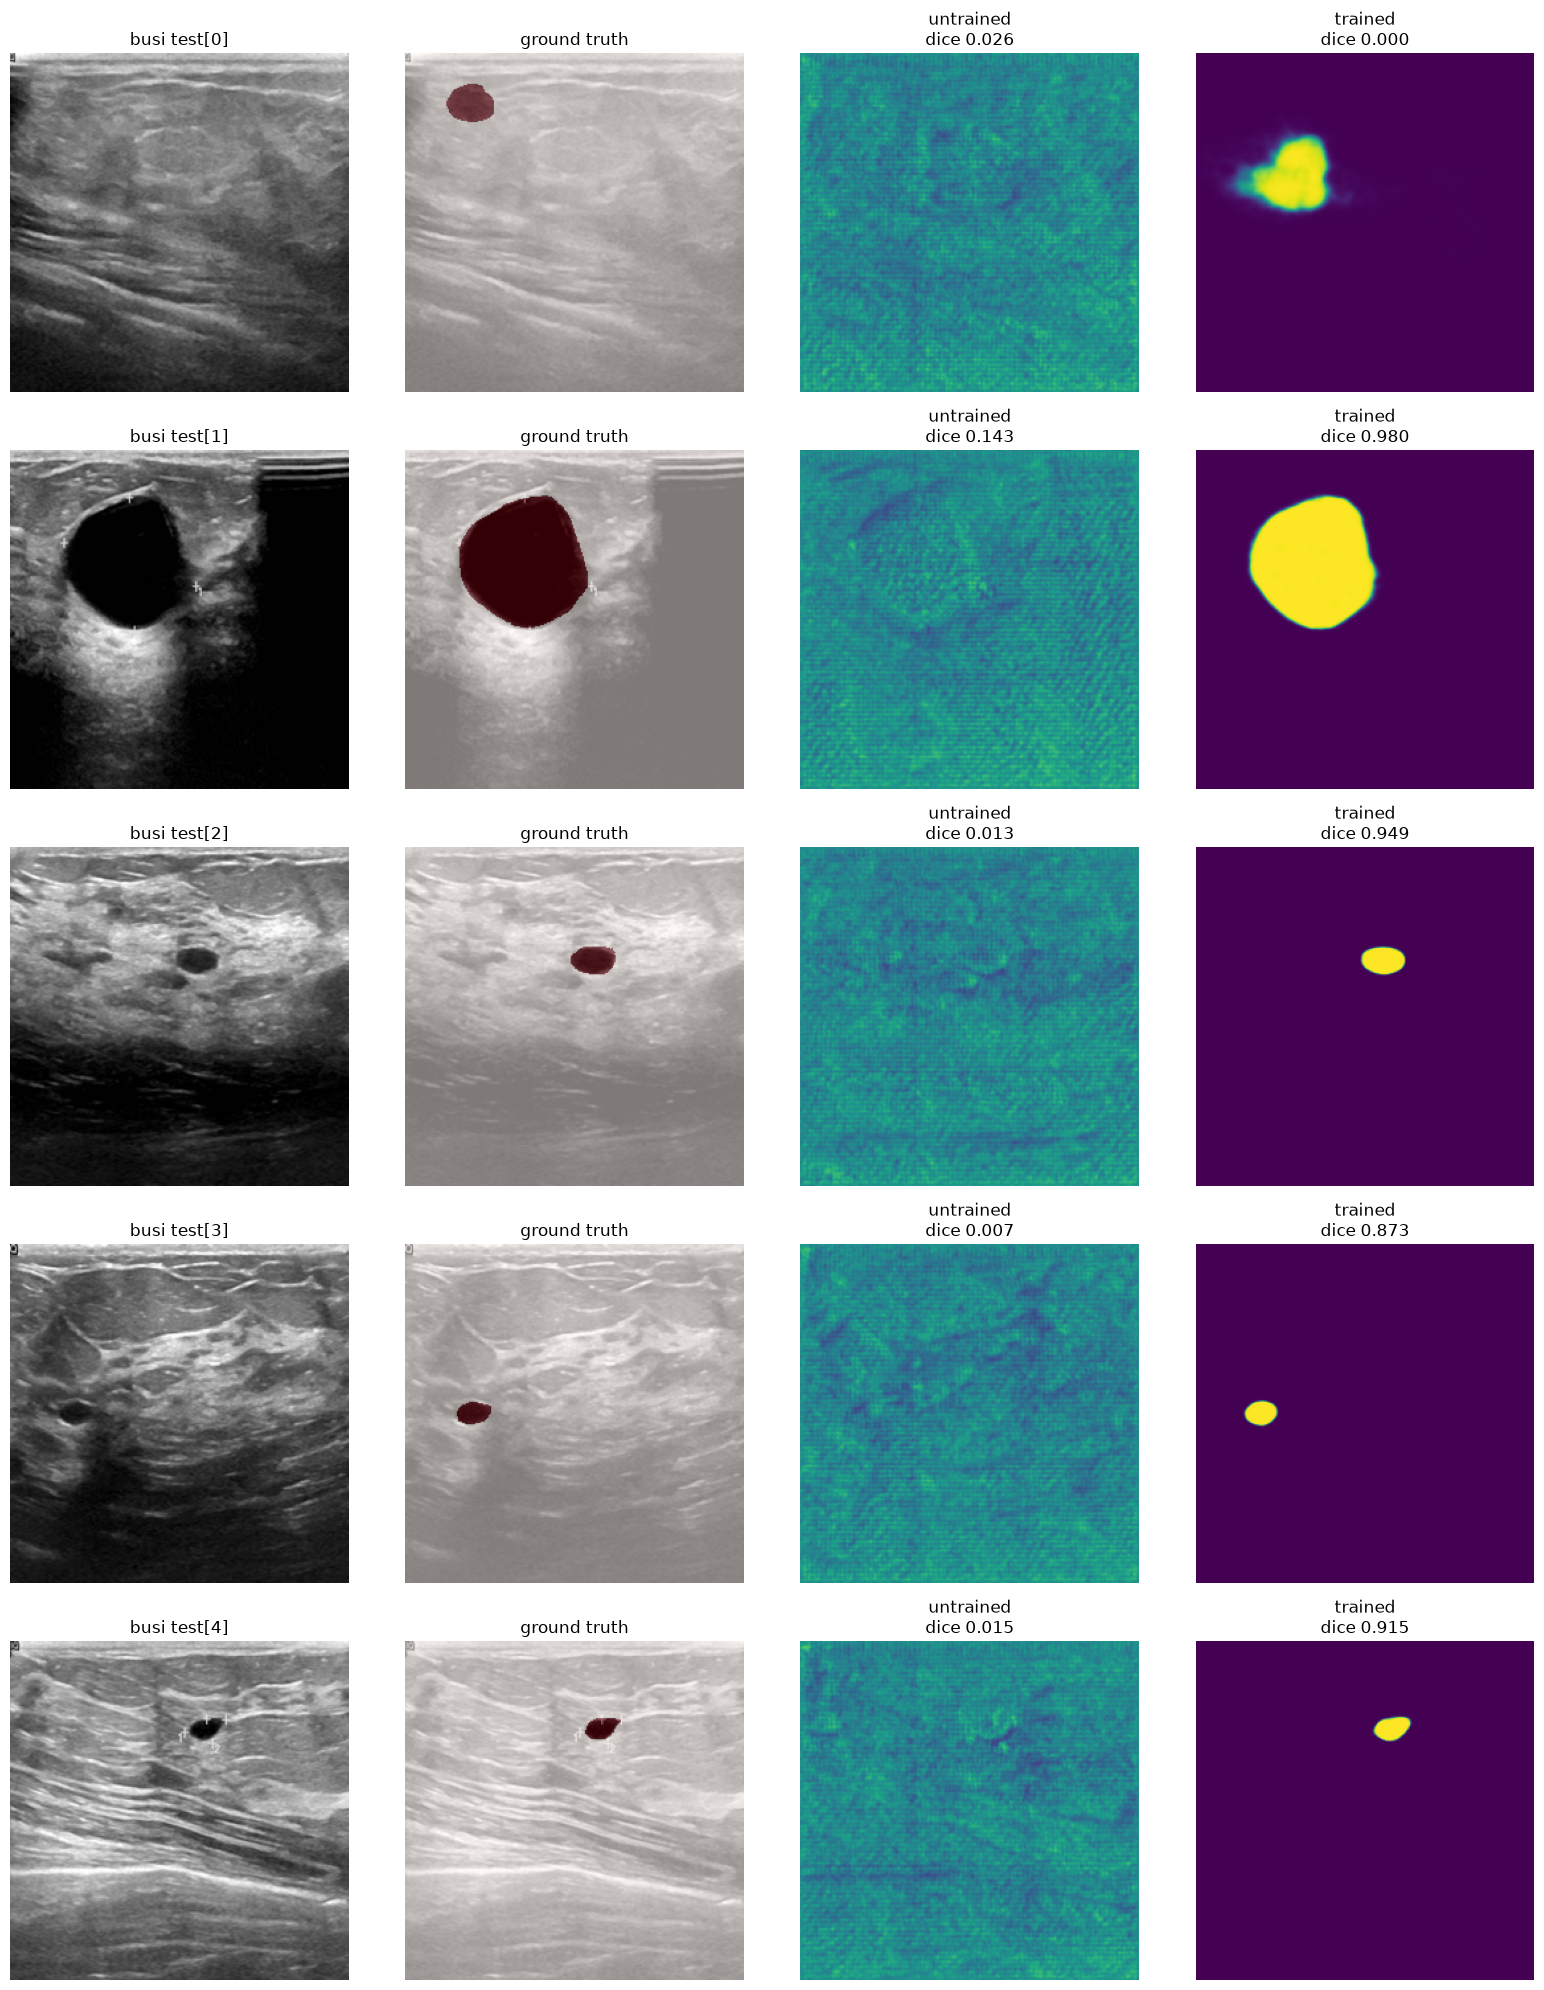

In [7]:
# --- BUSI (grayscale ultrasound, weak boundaries) ---
busi_dice, busi_nsd = run_dataset("busi", model, baseline)

kvasir: ckpt epoch 14 (val 0.9280)  |  TEST 200 imgs -> mean Dice 0.9095  mean NSD 0.4161


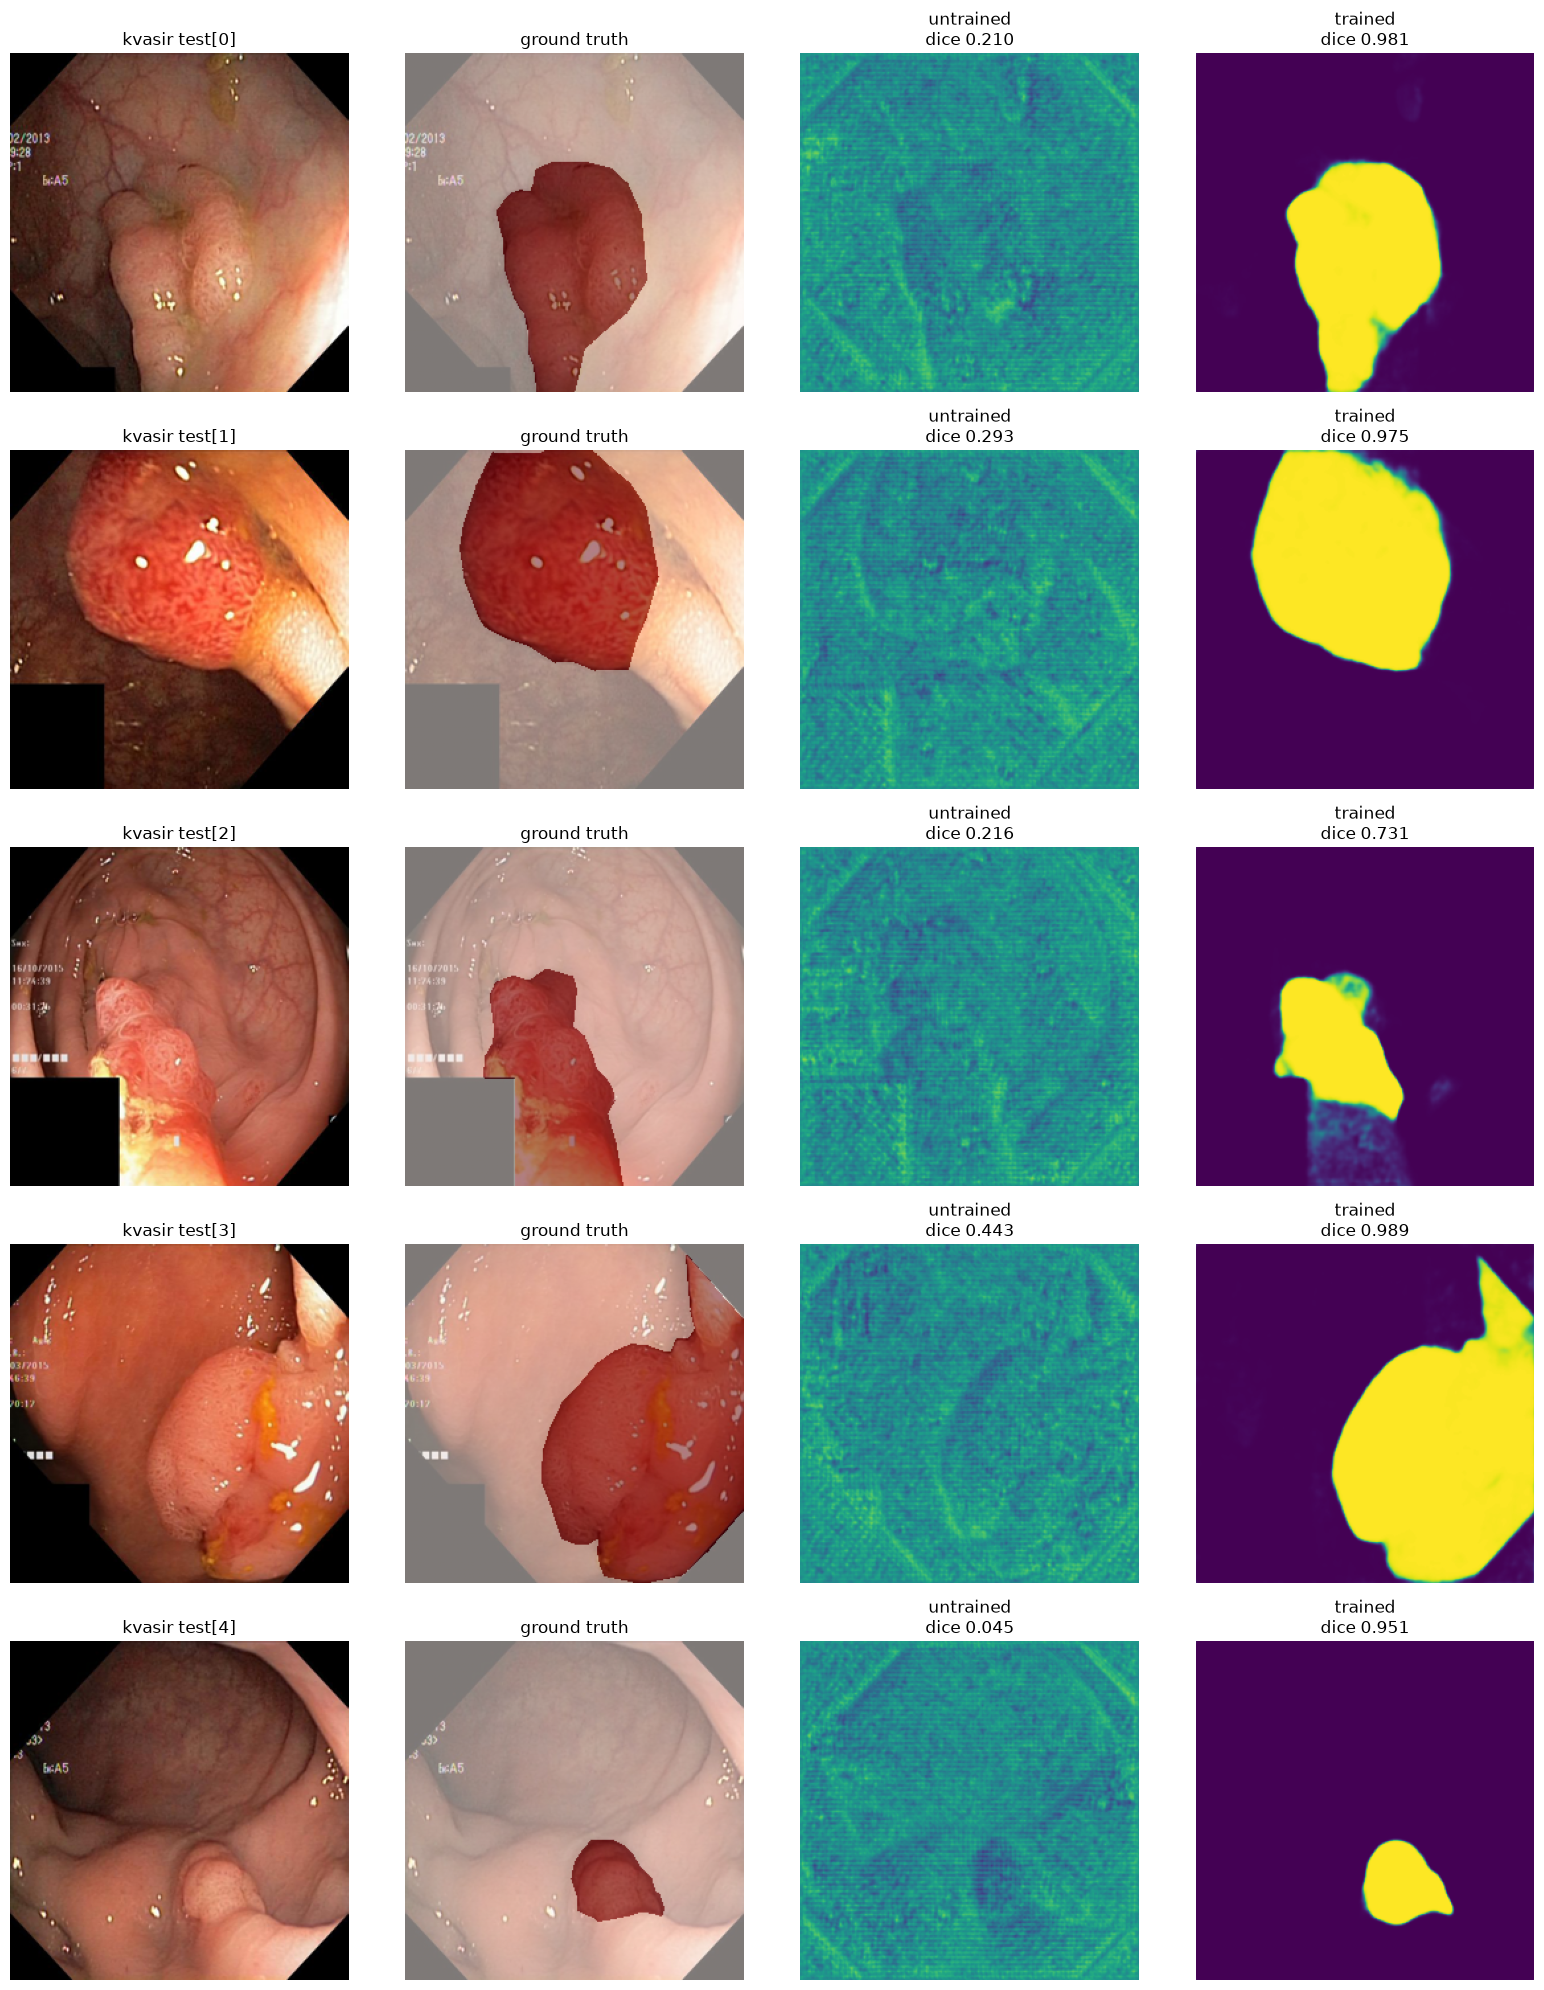


=== TEST SET COMPARISON ===
BUSI   (ultrasound, weak boundaries):  Dice 0.7670  NSD 0.2191
Kvasir (endoscopy, clear boundaries):  Dice 0.9095  NSD 0.4161


In [8]:
# --- Kvasir (RGB endoscopy, clear boundaries) ---
kvasir_dice, kvasir_nsd = run_dataset("kvasir", model, baseline)

print("\n=== TEST SET COMPARISON ===")
print(f"BUSI   (ultrasound, weak boundaries):  Dice {busi_dice:.4f}  NSD {busi_nsd:.4f}")
print(f"Kvasir (endoscopy, clear boundaries):  Dice {kvasir_dice:.4f}  NSD {kvasir_nsd:.4f}")

## 5. Cross-dataset test: the BUSI-trained model on Kvasir
Out-of-distribution / domain-shift test: the frozen SAM 3 backbone is general, but
the trained head + adapters learned the BUSI task, so expect partial transfer.
Note the absolute numbers are flattered by Kvasir's large central polyps (Dice
rewards covering big targets); the honest signal is trained vs untrained.

Kvasir test images: 200


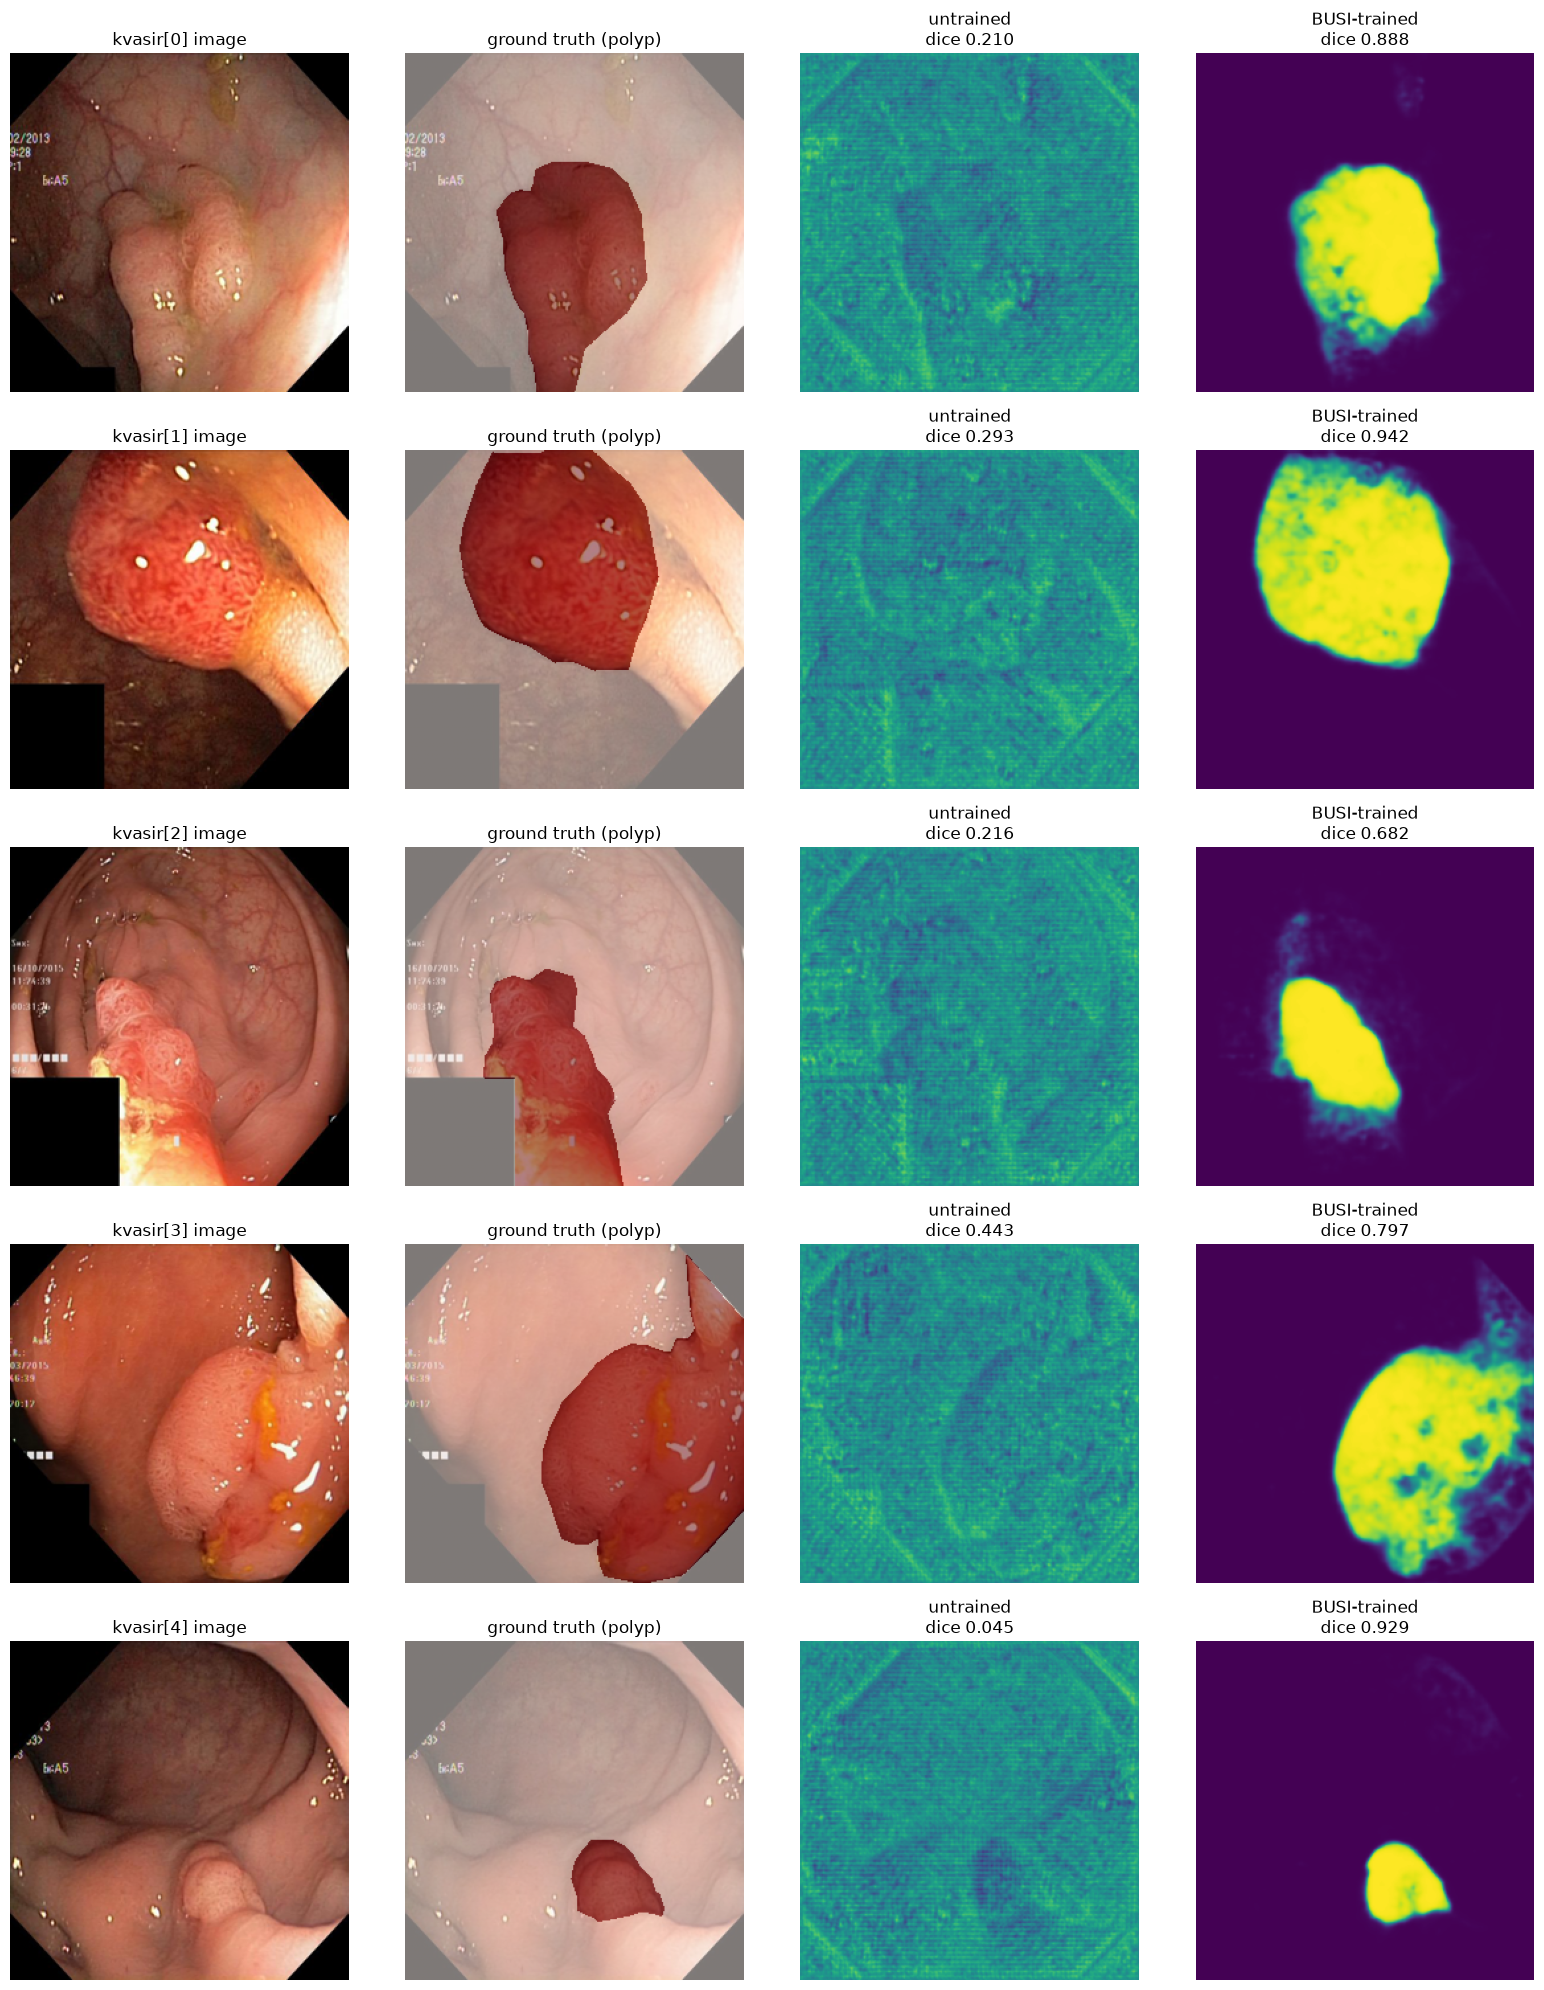

In [9]:
# Cross-dataset: the BUSI-trained model on Kvasir (domain-shift test). Load BUSI
# weights explicitly so this cell is self-contained regardless of run order
# (section 6 leaves `model` holding Kvasir weights).
# `baseline` is the untrained reference. Columns: image | GT polyp | untrained | BUSI-trained.
model.load_state_dict(torch.load("../checkpoints/sam3_lora_busi_full/best.pt", map_location=device)["model"])

kv_ds = build_dataloaders(DataConfig.from_yaml("../configs/data/kvasir.yaml"))["test"].dataset
print("Kvasir test images:", len(kv_ds))

KV_INDICES = [0, 1, 2, 3, 4]
rows = len(KV_INDICES)
fig, axes = plt.subplots(rows, 4, figsize=(16, 4 * rows))
for row, idx in enumerate(KV_INDICES):
    s = kv_ds[idx]
    img, m = s["image"], s["mask"][0]
    prob_u = predict_prob(baseline, img)            # untrained (random head)
    prob_t = predict_prob(model, img)               # BUSI-trained model on a Kvasir image
    img_np = img.permute(1, 2, 0).numpy()
    axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"kvasir[{idx}] image")
    axes[row, 1].imshow(img_np); axes[row, 1].imshow(m, cmap="Reds", alpha=0.5)
    axes[row, 1].set_title("ground truth (polyp)")
    axes[row, 2].imshow(prob_u, cmap="viridis", vmin=0, vmax=1)
    axes[row, 2].set_title(f"untrained\ndice {dice_of(prob_u, m):.3f}")
    axes[row, 3].imshow(prob_t, cmap="viridis", vmin=0, vmax=1)
    axes[row, 3].set_title(f"BUSI-trained\ndice {dice_of(prob_t, m):.3f}")
    for a in axes[row]:
        a.axis("off")
plt.tight_layout(); plt.show()

## 6. Learning curves (train loss + val Dice/NSD over epochs)
The per-epoch history is NOT in the checkpoint (best.pt only stores the single best
epoch). It's in the SLURM training logs — the `epoch N: train_loss=... val_dice=...`
lines. We parse those and plot the trend.

Copy the log files down from the cluster first (see the scp command in chat),
then point the calls below at the right job ids (BUSI vs Kvasir full runs).

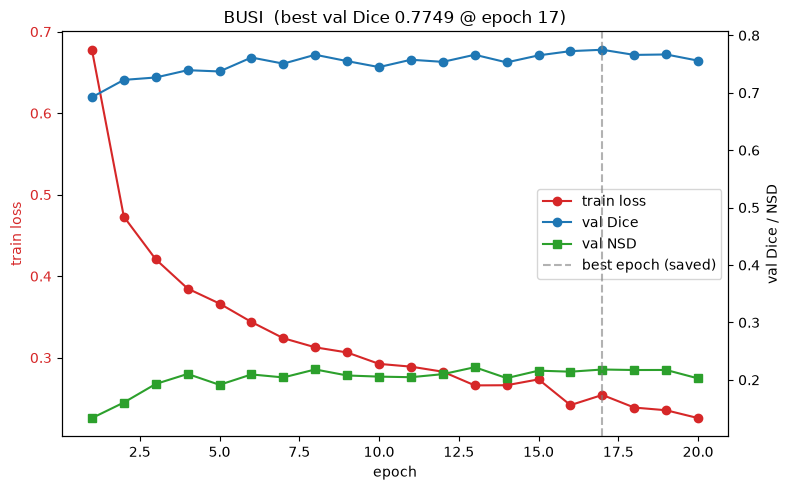

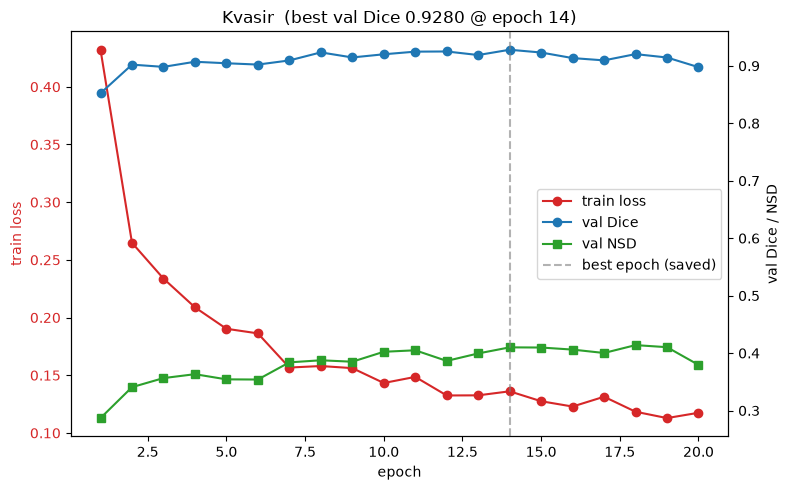

In [10]:
import re

def parse_log(path):
    """Extract per-epoch (train_loss, val_dice, val_nsd) from a SLURM training log."""
    pat = re.compile(r"epoch (\d+): train_loss=([\d.]+)\s+val_dice=([\d.]+)\s+val_nsd=([\d.]+)")
    rows = [m for m in (pat.search(l) for l in open(path)) if m]
    ep = [int(m.group(1)) for m in rows]
    return ep, [float(m.group(2)) for m in rows], [float(m.group(3)) for m in rows], [float(m.group(4)) for m in rows]

def plot_curve(path, title):
    ep, tl, vd, vn = parse_log(path)
    fig, ax1 = plt.subplots(figsize=(8, 5))
    l1, = ax1.plot(ep, tl, "C3-o", label="train loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss", color="C3")
    ax1.tick_params(axis="y", labelcolor="C3")
    ax2 = ax1.twinx()
    l2, = ax2.plot(ep, vd, "C0-o", label="val Dice")
    l3, = ax2.plot(ep, vn, "C2-s", label="val NSD")
    ax2.set_ylabel("val Dice / NSD")
    best = max(range(len(vd)), key=lambda i: vd[i])
    lbest = ax2.axvline(ep[best], ls="--", c="gray", alpha=0.6, label="best epoch (saved)")
    lines = [l1, l2, l3, lbest]
    ax1.legend(lines, [l.get_label() for l in lines], loc="center right")
    plt.title(f"{title}  (best val Dice {vd[best]:.4f} @ epoch {ep[best]})")
    plt.tight_layout(); plt.show()

# point these at your actual full-run log files (check the job ids in slurm_outs/)
plot_curve("../slurm_outs/slurm_5525699.out", "BUSI")
plot_curve("../slurm_outs/slurm_5526204.out", "Kvasir")